# Inferential Statistics: Python Examples

Introductory examples with NumPy, SciPy, and Matplotlib. Results should always be interpreted in context.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
rng = np.random.default_rng(42)
print('NumPy:', np.__version__)
print('SciPy:', stats.__version__ if hasattr(stats, '__version__') else 'installed')


NumPy: 2.3.5
SciPy: installed


## 1. Estimate and standard error

In [2]:
sample = np.array([51, 49, 52, 48, 50, 53, 47, 51], dtype=float)
n = len(sample)
mean = sample.mean()
sd = sample.std(ddof=1)
se = sd / np.sqrt(n)
print('n:', n, 'mean:', round(mean, 3), 'sample SD:', round(sd, 3), 'SE:', round(se, 3))


n: 8 mean: 50.125 sample SD: 2.031 SE: 0.718


## 2. Confidence interval for a mean using a t critical value

In [3]:
confidence = 0.95
alpha = 1 - confidence
t_critical = stats.t.ppf(1 - alpha/2, df=n-1)
ci = (mean - t_critical*se, mean + t_critical*se)
print('95% t interval:', tuple(round(v, 3) for v in ci))


95% t interval: (np.float64(48.427), np.float64(51.823))


## 3. One-sample t-test

In [4]:
x = np.array([11, 12, 10, 13, 9], dtype=float)
result = stats.ttest_1samp(x, popmean=10)
print('t statistic:', round(float(result.statistic), 4))
print('p-value:', round(float(result.pvalue), 4))
print('sample mean:', round(float(x.mean()), 3))


t statistic: 1.4142
p-value: 0.2302
sample mean: 11.0


A p-value is interpreted under the null model and test assumptions. Pair it with an effect estimate and interval.

## 4. Welch's independent two-sample t-test

In [5]:
group_a = np.array([12, 14, 13, 15, 11], dtype=float)
group_b = np.array([10, 9, 12, 11, 8], dtype=float)
result = stats.ttest_ind(group_a, group_b, equal_var=False)
print('Mean difference (A - B):', round(float(group_a.mean() - group_b.mean()), 3))
print('t statistic:', round(float(result.statistic), 4))
print('p-value:', round(float(result.pvalue), 4))


Mean difference (A - B): 3.0
t statistic: 3.0
p-value: 0.0171


## 5. Paired t-test

In [6]:
before = np.array([10, 12, 9, 14, 11], dtype=float)
after = np.array([11, 13, 10, 15, 12], dtype=float)
differences = after - before
print('Mean paired change:', float(differences.mean()))
print(stats.ttest_rel(after, before))


Mean paired change: 1.0
TtestResult(statistic=np.float64(inf), pvalue=np.float64(0.0), df=np.int64(4))


/opt/pyvenv/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:430: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  return hypotest_fun_in(*args, **kwds)


## 6. Chi-square test of independence

In [7]:
table = np.array([[30, 20], [15, 35]])
chi2, p_value, dof, expected = stats.chi2_contingency(table)
print('Chi-square:', round(float(chi2), 4), 'p-value:', round(float(p_value), 4), 'df:', dof)
print('Expected counts:\n', expected)


Chi-square: 7.9192 p-value: 0.0049 df: 1
Expected counts:
 [[22.5 27.5]
 [22.5 27.5]]


## 7. Pearson correlation

In [8]:
x = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([2, 4, 5, 4, 6], dtype=float)
r, p_value = stats.pearsonr(x, y)
print('Pearson r:', round(float(r), 4), 'p-value:', round(float(p_value), 4))


Pearson r: 0.8528 p-value: 0.0663


Correlation describes linear association, not causation. Check plots, outliers, and the study design.

## 8. Sampling distribution of the mean

In [9]:
population = rng.normal(loc=50, scale=10, size=10000)
means = np.array([rng.choice(population, size=40, replace=False).mean() for _ in range(500)])
print('Population mean:', round(float(population.mean()), 3))
print('Mean of sample means:', round(float(means.mean()), 3))
print('SD of sample means:', round(float(means.std()), 3))


Population mean: 49.898
Mean of sample means: 49.943
SD of sample means: 1.586


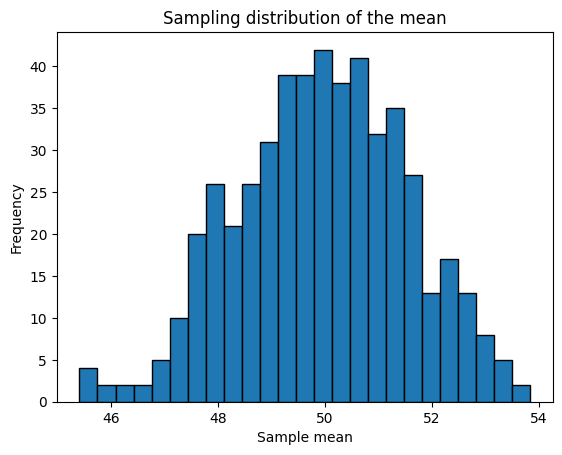

In [10]:
plt.hist(means, bins=25, edgecolor='black')
plt.xlabel('Sample mean')
plt.ylabel('Frequency')
plt.title('Sampling distribution of the mean')
plt.show()


## 9. Multiple testing illustration

In [11]:
p_values = np.array([0.01, 0.03, 0.04, 0.20, 0.50])
alpha = 0.05
bonferroni_threshold = alpha / len(p_values)
print('Unadjusted discoveries:', int((p_values < alpha).sum()))
print('Bonferroni threshold:', bonferroni_threshold)
print('Bonferroni discoveries:', int((p_values < bonferroni_threshold).sum()))


Unadjusted discoveries: 3
Bonferroni threshold: 0.01
Bonferroni discoveries: 0


## Key takeaways

- State hypotheses and assumptions before interpreting a test.
- Report effect sizes and confidence intervals alongside p-values.
- A non-significant result is not proof of no effect; significance is not proof of importance.
- Sampling design and data quality are central to valid inference.